# The Care Gap: Who Goes Without Mental Health Care

Judy Chen

Figures 1–7 use [CPES, 2001–2003](https://www.icpsr.umich.edu/web/ICPSR/studies/20240). Percentages and averages use survey weights; n counts respondents, and error bars show 95% confidence intervals. Interference is rated from 0 (none) to 10 (very severe) for the worst period of the past year. See the [final article](final/final.pdf) for the narrative and data limitations.

## Setup

Run this notebook from `static-viz-project/`, with the two source files in `data/` ([download instructions](data/README.md)). Restart the kernel and run all cells in order. PNG copies are saved in `final/figures/`.

If needed, install the packages first:

```sh
python -m pip install numpy pandas scipy "altair>=6.3,<7" vl-convert-python jupyterlab
```

In [1]:
from pathlib import Path
import zipfile

import altair as alt
import numpy as np
import pandas as pd
from scipy.stats import t

# Run this notebook from static-viz-project; source files stay in the
# ignored data folder.
DATA_DIR = Path('data')
CPES_PATH = DATA_DIR / '20240-0001-Data.dta'
NSDUH_PATH = DATA_DIR / 'nsduh2024.zip'
FIGURE_DIR = Path('final/figures')
FIGURE_DIR.mkdir(exist_ok=True)

# Display static PNGs in the notebook.
alt.renderers.enable("png")

BLUE = "#536D9A"
# Each disorder keeps the same color across all figures.
DISORDER_COLORS = {
    "Depression": "#1b9e77",
    "Generalized anxiety": "#d95f02",
    "Panic disorder": "#7570b3",
    "Social phobia": "#e7298a",
    "Agoraphobia": "#377eb8",
    "PTSD": "#e6ab02",
}
DISORDER_LABELS = list(DISORDER_COLORS)
DISORDER_SCALE = alt.Scale(domain=DISORDER_LABELS,
                           range=list(DISORDER_COLORS.values()))
NEUTRAL = "#7C8289"
# Care categories keep the same colors across the 2024 figures.
CARE_COLORS = {
    "Both": "#59A14F",
    "Professional contact only": "#4E79A7",
    "Medication only": "#E15759",
    "Neither reported": "#8C8C8C",
}
CPES_SOURCE = "CPES, 2001–2003"
NSDUH_SOURCE = "NSDUH, 2024"


def save_chart(chart, filename, title, notes):
    """
    Apply the shared style to a chart, export it as a PNG, and return it.

    Inputs:
      chart (alt.Chart): the chart to style and save.
      filename (str): the PNG file name, saved in FIGURE_DIR.
      title (str): the chart title.
      notes (list of str): subtitle lines (source and reading notes).

    Returns:
      (alt.Chart) the styled chart, for display in the notebook.
    """
    chart = (
        chart.properties(title=alt.TitleParams(text=title, subtitle=notes,
                                               anchor="start"))
        .configure(background="white", font="Arial", padding=12)
        .configure_axis(
            labelFontSize=11, titleFontSize=12, titlePadding=9,
            gridColor="#E5E5E5", tickCount=5, domain=False, ticks=False,
            labelColor="#333333", titleColor="#111111",
            labelLimit=230,
        )
        .configure_legend(labelFontSize=11, titleFontSize=11, padding=8)
        .configure_title(fontSize=14, subtitleFontSize=10,
                         subtitleColor="#555555", offset=12)
        .configure_header(labelFontSize=11, labelFontWeight="normal",
                          title=None)
        .configure_view(stroke=None)
    )
    chart.save(FIGURE_DIR / filename, scale_factor=2)
    return chart

In [2]:
# Match each disorder to its CPES questionnaire variables.
# diagnosis is past-year status; ever_help is lifetime help.
# domains are home management, close relationships, and social life, in that
# order.
DISORDERS = {
    "Major depressive disorder": {
        "diagnosis": "V07655", "social": "V00992",
        "domains": ["V00989", "V00991", "V00992"],
        "professional_care": "V01013", "ever_help": "V00995",
    },
    "Generalized anxiety disorder": {
        "diagnosis": "V07613", "social": "V01870",
        "domains": ["V01867", "V01869", "V01870"],
        "professional_care": "V01891", "ever_help": "V01874",
    },
    "Panic disorder": {
        "diagnosis": "V07716", "social": "V01353",
        "domains": ["V01350", "V01352", "V01353"],
        "professional_care": "V01394", "ever_help": "V01357",
    },
    "Social phobia": {
        "diagnosis": "V07748", "social": "V01579",
        "domains": ["V01576", "V01578", "V01579"],
        "professional_care": "V01621", "ever_help": "V01583",
    },
    "Agoraphobia without panic disorder": {
        "diagnosis": "V07513", "social": "V01692",
        "domains": ["V01689", "V01691", "V01692"],
        "professional_care": "V01734", "ever_help": "V01697",
    },
    "PTSD": {
        "diagnosis": "V07725", "social": "V04037",
        "domains": ["V04034", "V04036", "V04037"],
        "professional_care": "V04040", "ever_help": None,
    },
}
# Antidepressant use, without identifying the condition treated.
ANTIDEPRESSANTS = "V02614"
# Load only the variables needed for the figures and the survey design.
cpes_columns = {"CPESCASE", "NCNLWTLG", "SESTRAT", "SECLUSTR"}
for spec in DISORDERS.values():
    cpes_columns.update([
        spec["diagnosis"], spec["social"], spec["professional_care"],
        spec["ever_help"], *spec["domains"],
    ])
cpes_columns.discard(None)
cpes_columns.add(ANTIDEPRESSANTS)

# Keep the common NCS-R Part 2 + NLAAS pool with its official combined weight.
cpes_raw = pd.read_stata(CPES_PATH, columns=sorted(cpes_columns),
                         convert_categoricals=False)
# Positive NCNLWTLG weights identify respondents in this combined survey pool.
cpes = cpes_raw.loc[cpes_raw["NCNLWTLG"].gt(0)].copy()
# Check the file size, unique respondent IDs, and selected pool size.
assert len(cpes_raw) == 20_013 and cpes_raw["CPESCASE"].is_unique
assert len(cpes) == 10_341


care_values = {}
care_coverage = []
for name, spec in DISORDERS.items():
    observed = cpes[spec["professional_care"]]
    # CPES uses 1=yes and 5=no; recode to 1/0 and leave unknown answers
    # missing.
    care = observed.map({1: 1.0, 5: 0.0})
    inferred_no = pd.Series(False, index=cpes.index)
    if spec["ever_help"] is not None:
        never_help = cpes[spec["ever_help"]].eq(5)
        assert not (never_help & observed.eq(1)).any()
        # An explicit lifetime "no" rules out past-year help for this
        # disorder.
        inferred_no = observed.isna() & never_help
        care = care.mask(inferred_no, 0.0)
    # PTSD's lifetime item concerns a selected event: do not infer from it.
    care_values[name] = care
    cases = cpes[spec["diagnosis"]].eq(1)
    # Track known responses because care denominators differ across disorders.
    care_coverage.append({"name": name, "cases": int(cases.sum()),
                          "known": int((cases & care.notna()).sum()),
                          "inferred_no": int((cases & inferred_no).sum())})
assert [r["known"] for r in care_coverage] == [916, 496, 353, 849, 220, 257]


# NSDUH fields cover depression, impairment, care, insurance, and sampling
# design.
nsduh_columns = [
    "IRAMDEYR", "IRAMDEIMP", "ATXMDEYR", "ARXMDEYR",
    "ANALWT2_C", "VESTR_C", "VEREP", "IRINSUR4",
]
# Read directly from the ZIP; a period in the data marks a missing response.
with zipfile.ZipFile(NSDUH_PATH) as archive:
    with archive.open("NSDUH_2024_Tab.txt") as stream:
        nsduh_raw = pd.read_csv(stream, sep="\t", usecols=nsduh_columns,
                                na_values=["."])
assert len(nsduh_raw) == 58_633
# Adult depression status uses 0=no and 1=yes; then keep past-year cases.
nsduh_adults = nsduh_raw.loc[nsduh_raw["IRAMDEYR"].isin([0, 1])].copy()
nsduh_mde = nsduh_adults.loc[nsduh_adults["IRAMDEYR"].eq(1)].copy()
# Require known answers to both care items; unknown answers are not "no."
care_known = (nsduh_mde["ATXMDEYR"].isin([0, 1])
              & nsduh_mde["ARXMDEYR"].isin([0, 1]))
nsduh_care = nsduh_mde.loc[care_known].copy()
# Check "both" first so the four care categories do not overlap.
nsduh_care["care_group"] = np.select(
    [
        nsduh_care["ATXMDEYR"].eq(1) & nsduh_care["ARXMDEYR"].eq(1),
        nsduh_care["ATXMDEYR"].eq(1),
        nsduh_care["ARXMDEYR"].eq(1),
    ],
    ["Both", "Professional contact only", "Medication only"],
    default="Neither reported",
)
nsduh_care["reported_either"] = (nsduh_care["ATXMDEYR"].eq(1)
                                 | nsduh_care["ARXMDEYR"].eq(1))
assert len(nsduh_adults) == 47_299 and len(nsduh_mde) == 5_205
assert len(nsduh_care) == 5_008 and (~care_known).sum() == 197

### Survey confidence intervals

`survey_mean()` is an extra method beyond the class examples. It calculates survey-weighted estimates and uses Taylor linearization to account for strata and clusters in the confidence intervals. See the [method reference](https://support.sas.com/documentation/cdl/en/statug/68162/HTML/default/statug_surveymeans_details06.htm).

In [3]:
def survey_mean(frame, values, domain=None, *, weight, strata, cluster):
    """
    Calculate a weighted mean and a 95% CI using the survey design.

    Use Taylor linearization and keep the full sample when estimating a
    subgroup.

    Inputs:
      frame (pd.DataFrame): the full analysis pool with design columns.
      values (pd.Series): the answer for each respondent; missing answers
        are left out of the mean.
      domain (pd.Series of bool or None): the subgroup to estimate for;
        None uses everyone.
      weight, strata, cluster (str): the names of the survey weight,
        stratum, and sampling-cluster columns in frame.

    Returns:
      (dict) the estimate, standard error, lower and upper 95% bounds,
        respondent count n, and design degrees of freedom.

    Raises ValueError for invalid weights, missing design identifiers, an
    empty domain, or a stratum with a single sampling cluster.
    """
    # domain selects a subgroup; only its non-missing answers enter the mean.
    y = pd.Series(values, index=frame.index, dtype=float)
    active = y.notna()
    if domain is not None:
        active &= (pd.Series(domain, index=frame.index)
                   .fillna(False).astype(bool))
    w = frame[weight].astype(float)
    if not np.isfinite(w).all() or not w.gt(0).all():
        raise ValueError("Use a full analysis pool with finite, positive "
                         "survey weights.")
    if frame[[strata, cluster]].isna().any().any():
        raise ValueError("Missing survey design identifiers need "
                         "investigation.")
    denominator = w.loc[active].sum()
    if denominator <= 0:
        raise ValueError("No valid weighted observations in the requested "
                         "domain.")
    # For 0/1 answers, a weighted mean is the estimated population proportion.
    estimate = float(np.average(y.loc[active], weights=w.loc[active]))
    # Other respondents contribute zero here but stay in the sampling design.
    residual = (y - estimate).where(active, 0.0)
    # Estimate variation between clusters within each sampling stratum.
    design = frame[[strata, cluster]].copy()
    design["linearized"] = w * residual / denominator
    psu_totals = (design.groupby([strata, cluster], observed=True)
                  ["linearized"].sum())
    components = psu_totals.groupby(level=0).agg(["count", "sum"])
    if components["count"].lt(2).any():
        raise ValueError("A single-PSU stratum needs a documented variance "
                         "treatment.")
    centered = psu_totals - psu_totals.groupby(level=0).transform("mean")
    square_sums = centered.pow(2).groupby(level=0).sum()
    m = components["count"]
    # Combine the stratum contributions to calculate the standard error.
    variance = float((m / (m - 1) * square_sums).sum())
    se = float(np.sqrt(max(variance, 0)))
    # The survey design determines the t multiplier for a 95% interval.
    degrees_freedom = int((m - 1).sum())
    critical = float(t.ppf(0.975, degrees_freedom))
    return {
        "estimate": estimate, "se": se,
        "lower": estimate - critical * se, "upper": estimate + critical * se,
        "n": int(active.sum()), "design_df": degrees_freedom,
    }

# Supply the weight, stratum, and sampling-cluster columns for each survey.
CPES_DESIGN = {"weight": "NCNLWTLG", "strata": "SESTRAT",
               "cluster": "SECLUSTR"}
NSDUH_DESIGN = {"weight": "ANALWT2_C", "strata": "VESTR_C",
                "cluster": "VEREP"}

## Figure 1 · Past-year prevalence

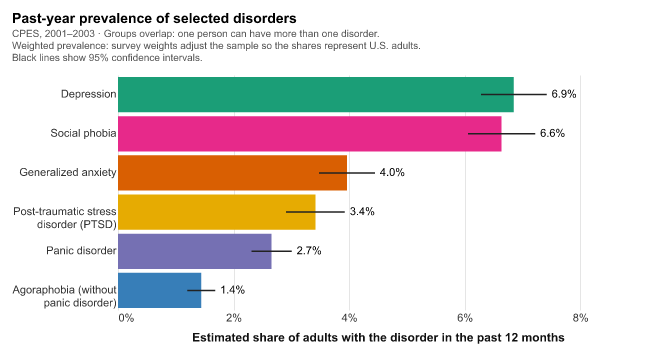

In [4]:
prevalence_rows = []
# Estimate each disorder's past-year prevalence among all adults in the pool.
for label, spec in zip(DISORDER_LABELS, DISORDERS.values()):
    # CPES codes diagnoses as 1=yes and 5=no.
    has_disorder = cpes[spec["diagnosis"]].map({1: 1., 5: 0.})
    result = survey_mean(cpes, has_disorder, **CPES_DESIGN)
    prevalence_rows.append({"name": label, **result})
prevalence = pd.DataFrame(prevalence_rows).sort_values("estimate")


def prevalence_chart(df):
    """
    Draw past-year prevalence by disorder as bars with 95% CIs (Figure 1).

    Inputs:
      df (pd.DataFrame): one row per disorder, with name, estimate, lower,
        and upper columns from survey_mean().

    Returns:
      (alt.LayerChart) bars, interval lines, and value labels.
    """
    disorder_order = (df.sort_values("estimate", ascending=False)["name"]
                      .tolist())
    base = alt.Chart(df).encode(
        # Spell out PTSD and the agoraphobia definition, which readers found
        # unclear.
        y=alt.Y("name:N", sort=disorder_order, title=None,
                axis=alt.Axis(
                    labelExpr="datum.label == 'PTSD' ? "
                              "['Post-traumatic stress', 'disorder (PTSD)'] : "
                              "datum.label == 'Agoraphobia' ? "
                              "['Agoraphobia (without', 'panic disorder)'] "
                              ": datum.label",
                    labelLineHeight=13)),
    )
    bars = base.mark_bar().encode(
        x=alt.X("estimate:Q",
                title="Estimated share of adults with the disorder in the "
                      "past 12 months",
                axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .09], nice=False)),
        color=alt.Color("name:N", legend=None,
                        scale=DISORDER_SCALE),
    )
    intervals = base.mark_rule(color="#222222", strokeWidth=1.5).encode(
        x="lower:Q", x2="upper:Q",
    )
    labels = base.mark_text(align="left", dx=5).encode(
        x="upper:Q", text=alt.Text("estimate:Q", format=".1%"),
    )
    return (bars + intervals + labels).properties(width=520, height=235)


save_chart(
    prevalence_chart(prevalence), "1.png",
    "Past-year prevalence of selected disorders",
    [CPES_SOURCE + " · Groups overlap: one person can have more than one "
     "disorder.",
     "Weighted prevalence: survey weights adjust the sample so the shares "
     "represent U.S. adults.",
     "Black lines show 95% confidence intervals."],
)

## Figure 2 · Which disorders occurred together?

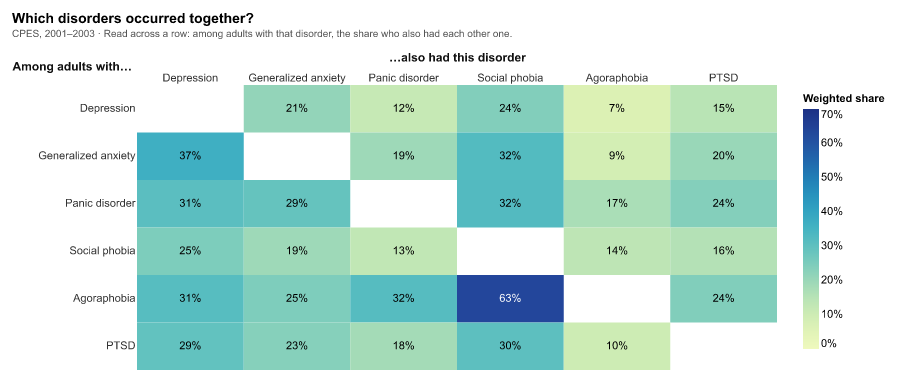

In [5]:
diagnosis_columns = [spec["diagnosis"] for spec in DISORDERS.values()]
assert cpes[diagnosis_columns].isin([1, 5]).all().all()
diagnosis_flags = cpes[diagnosis_columns].eq(1).set_axis(DISORDER_LABELS,
                                                         axis=1)
cooccurrence_rows = []
for disorder in DISORDER_LABELS:
    # The row's disorder defines the group used as the denominator.
    group = diagnosis_flags[disorder]
    for other_disorder in DISORDER_LABELS:
        if disorder == other_disorder:
            continue
        share = np.average(diagnosis_flags.loc[group, other_disorder],
                           weights=cpes.loc[group, "NCNLWTLG"])
        cooccurrence_rows.append({"disorder": disorder,
                                  "also_had": other_disorder,
                                  "share": share})
cooccurrence_df = pd.DataFrame(cooccurrence_rows)


def cooccurrence_chart(df):
    """
    Draw a heatmap of how often each pair of disorders co-occurred
    (Figure 2).

    Inputs:
      df (pd.DataFrame): one row per ordered pair, with disorder (the
        group), also_had (the other disorder), and share columns.

    Returns:
      (alt.LayerChart) colored cells with percentage labels.
    """
    base = alt.Chart(df).encode(
        # Column labels sit on top, so each row reads left to right like a
        # sentence.
        x=alt.X("also_had:N", title="…also had this disorder",
                sort=DISORDER_LABELS,
                axis=alt.Axis(orient="top", labelAngle=0, titlePadding=8)),
        # A horizontal row title in the top-left corner.
        y=alt.Y("disorder:N", title="Among adults with…",
                sort=DISORDER_LABELS,
                axis=alt.Axis(titleAngle=0, titleAlign="left",
                              titleBaseline="bottom",
                              titleX=-125, titleY=-12)),
    )
    cells = base.mark_rect().encode(
        color=alt.Color(
            "share:Q", title="Weighted share",
            scale=alt.Scale(scheme="yellowgreenblue", domain=[0, .7],
                            nice=False),
            legend=alt.Legend(format="%",
                              values=[0, .1, .2, .3, .4, .5, .6, .7],
                              labelOverlap=False, gradientLength=240)),
    )
    # Switch text color only where the sequential palette becomes dark
    # enough.
    labels = base.mark_text().encode(
        text=alt.Text("share:Q", format=".0%"),
        color=alt.condition("datum.share > .5", alt.value("white"),
                            alt.value("black")),
    )
    return (cells + labels).properties(width=640, height=285)


save_chart(
    cooccurrence_chart(cooccurrence_df), "2.png",
    "Which disorders occurred together?",
    [CPES_SOURCE + " · Read across a row: among adults with that disorder, "
     "the share who also had each other one."],
)

## Figure 3 · Which disorder combinations were most common?

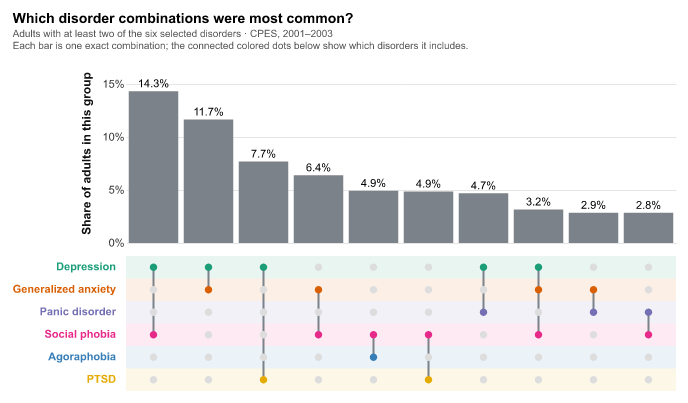

In [6]:
# Group the six yes/no columns directly: each group is one exact combination.
diagnosis_flags = cpes[diagnosis_columns].eq(1).set_axis(DISORDER_LABELS,
                                                         axis=1)
multi = diagnosis_flags.sum(axis=1).ge(2)
combination_weights = (
    diagnosis_flags.loc[multi].assign(weight=cpes.loc[multi, "NCNLWTLG"])
    .groupby(DISORDER_LABELS)["weight"].sum()
    .sort_values(ascending=False)
)
top_combinations = combination_weights.head(10).reset_index()
top_combinations["combination"] = [str(i + 1)
                                   for i in range(len(top_combinations))]
top_combinations["share"] = (top_combinations["weight"]
                             / combination_weights.sum())

combinations = top_combinations["combination"].tolist()
combination_df = top_combinations[["combination", "share"]]
membership_df = top_combinations.melt(
    id_vars="combination", value_vars=DISORDER_LABELS,
    var_name="disorder", value_name="included",
)
# Each connector runs from the first to the last disorder in its combination.
included_df = membership_df.loc[membership_df["included"]]
connector_df = included_df.groupby("combination")["disorder"].agg(
    first=lambda names: min(names, key=DISORDER_LABELS.index),
    last=lambda names: max(names, key=DISORDER_LABELS.index),
).reset_index()


def combinations_chart(bars_df, dots_df, links_df):
    """
    Draw the most common disorder combinations as bars above a dot matrix
    (Figure 3).

    Inputs:
      bars_df (pd.DataFrame): combination and share for each bar.
      dots_df (pd.DataFrame): combination, disorder, and included for
        each dot in the matrix.
      links_df (pd.DataFrame): combination with the first and last
        included disorder, for the connector lines.

    Returns:
      (alt.VConcatChart) the bar chart stacked above the dot matrix.
    """
    bars = alt.Chart(bars_df).mark_bar(color=NEUTRAL).encode(
        x=alt.X("combination:O", sort=combinations, axis=None),
        y=alt.Y("share:Q", title="Share of adults in this group",
                axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .17])),
    )
    labels = bars.mark_text(dy=-7).encode(
        text=alt.Text("share:Q", format=".1%"),
    )
    disorder_y = alt.Y("disorder:N", sort=DISORDER_LABELS,
                       scale=alt.Scale(domain=DISORDER_LABELS),
                       title=None, axis=None)
    disorder_rows = pd.DataFrame({"disorder": DISORDER_LABELS})
    # Faint bands repeat each disorder's color to help readers follow the
    # rows.
    row_bands = alt.Chart(disorder_rows).mark_rect(opacity=.10).encode(
        x=alt.value(0), x2=alt.value(550), y=disorder_y,
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    # Row names take their disorder's color, matching the dots.
    names = alt.Chart(disorder_rows).mark_text(
        align="right", dx=-10, fontSize=11, fontWeight="bold",
    ).encode(
        x=alt.value(0), y=disorder_y, text="disorder:N",
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    # Grey connectors tie each bar's dots into one column.
    links = alt.Chart(links_df).mark_rule(color=NEUTRAL, strokeWidth=2).encode(
        x=alt.X("combination:O", sort=combinations, axis=None),
        y=alt.Y("first:N", sort=DISORDER_LABELS,
                scale=alt.Scale(domain=DISORDER_LABELS), axis=None),
        y2="last:N",
    )
    dots = alt.Chart(dots_df).mark_point(filled=True, size=55,
                                         opacity=1).encode(
        x=alt.X("combination:O", sort=combinations, axis=None),
        y=disorder_y,
        color=alt.condition("datum.included",
                            alt.Color("disorder:N", scale=DISORDER_SCALE,
                                      legend=None),
                            alt.value("#DDDDDD")),
    )
    return alt.vconcat(
        (bars + labels).properties(width=550, height=180),
        (row_bands + names + links + dots).properties(width=550, height=135),
        spacing=8,
    ).resolve_scale(x="shared")


save_chart(
    combinations_chart(combination_df, membership_df, connector_df), "3.png",
    "Which disorder combinations were most common?",
    ["Adults with at least two of the six selected disorders · "
     + CPES_SOURCE,
     "Each bar is one exact combination; the connected colored dots below "
     "show which disorders it includes."],
)

## Figure 4 · Daily-life domains

Each symbol shows one domain's average score; shaded strips span the lowest and highest, not confidence intervals.

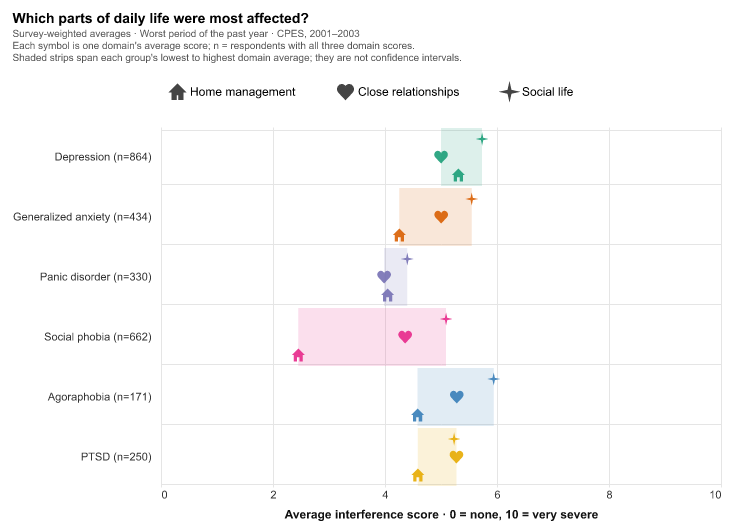

In [7]:
domain_means, complete_counts = [], []
for spec in DISORDERS.values():
    valid_scores = cpes[spec["domains"]].apply(
        lambda scores: scores.between(0, 10))
    valid = cpes[spec["diagnosis"]].eq(1) & valid_scores.all(axis=1)
    averages = []
    for variable in spec["domains"]:
        average = np.average(cpes.loc[valid, variable],
                             weights=cpes.loc[valid, "NCNLWTLG"])
        averages.append(average)
    domain_means.append(averages)
    complete_counts.append(int(valid.sum()))
assert complete_counts == [864, 434, 330, 662, 171, 250]


domains = ["Home management", "Close relationships", "Social life"]
domain_labels = [f"{label} (n={n:,})"
                 for label, n in zip(DISORDER_LABELS, complete_counts)]
domain_df = pd.DataFrame([
    {"disorder": domain_labels[row], "name": DISORDER_LABELS[row],
     "domain": domain, "mean_score": domain_means[row][col]}
    for row in range(6) for col, domain in enumerate(domains)
])
# Icons for each domain, as SVG paths that Vega-Lite accepts as point shapes.
HOUSE = ("M 0 -1 L 1 0 L 0.7 0 L 0.7 1 L 0.2 1 L 0.2 0.35 L -0.2 0.35 "
         "L -0.2 1 L -0.7 1 L -0.7 0 L -1 0 Z")
HEART = ("M 0 1 L -0.85 0.1 C -1.3 -0.4 -0.9 -1 -0.45 -0.95 "
         "C -0.2 -0.92 0 -0.7 0 -0.55 "
         "C 0 -0.7 0.2 -0.92 0.45 -0.95 C 0.9 -1 1.3 -0.4 0.85 0.1 Z")
STAR = ("M 0 -1 L 0.18 -0.18 L 1 0 L 0.18 0.18 L 0 1 L -0.18 0.18 L -1 0 "
        "L -0.18 -0.18 Z")


def domain_interference_chart(df):
    """
    Draw each disorder's average interference in three daily-life domains
    (Figure 4).

    Inputs:
      df (pd.DataFrame): one row per disorder and domain, with disorder
        (row label with n), name, domain, and mean_score columns.

    Returns:
      (alt.LayerChart) range strips with one icon per domain average.
    """
    # Light lines between rows separate the disorders.
    y = alt.Y("disorder:N", sort=domain_labels, title=None,
              axis=alt.Axis(grid=True, tickBand="extent", labelPadding=10))
    x_title = "Average interference score · 0 = none, 10 = very severe"
    x_scale = alt.Scale(domain=[0, 10], nice=False)
    # A pale strip spans the lowest and highest domain averages; it is not
    # uncertainty.
    strips = alt.Chart(df).transform_aggregate(
        lowest="min(mean_score)", highest="max(mean_score)",
        groupby=["disorder", "name"],
    ).mark_bar(size=58, opacity=.15).encode(
        y=y, x=alt.X("lowest:Q", title=x_title, scale=x_scale),
        x2="highest:Q",
        color=alt.Color("name:N", scale=DISORDER_SCALE, legend=None),
    )
    # Each domain gets its own line within a row, so markers do not overlap.
    points = alt.Chart(df).mark_point(filled=True, size=170,
                                      opacity=.9).encode(
        y=y,
        x=alt.X("mean_score:Q", title=x_title, scale=x_scale,
                axis=alt.Axis(values=[0, 2, 4, 6, 8, 10], tickCount=6,
                              labelOverlap=False)),
        yOffset=alt.YOffset("domain:N", sort=domains[::-1],
                            scale=alt.Scale(paddingOuter=.5)),
        color=alt.Color("name:N", scale=DISORDER_SCALE, legend=None),
        shape=alt.Shape(
            "domain:N", title=None,
            scale=alt.Scale(domain=domains, range=[HOUSE, HEART, STAR]),
            legend=alt.Legend(orient="top", direction="horizontal",
                              labelFontSize=12, symbolSize=220,
                              labelLimit=180, columnPadding=40,
                              symbolFillColor="#444444",
                              symbolStrokeColor="#444444",
                              symbolOpacity=1)),
    )
    return (strips + points).properties(width=560, height=360)


save_chart(
    domain_interference_chart(domain_df), "4.png",
    "Which parts of daily life were most affected?",
    ["Survey-weighted averages · Worst period of the past year · "
     + CPES_SOURCE,
     "Each symbol is one domain's average score; n = respondents with all "
     "three domain scores.",
     "Shaded strips span each group's lowest to highest domain average; "
     "they are not confidence intervals."],
)

## Figure 5 · Social-life interference distributions

Scores are whole numbers from 0 (none) to 10 (very severe), so each score gets its own bar.

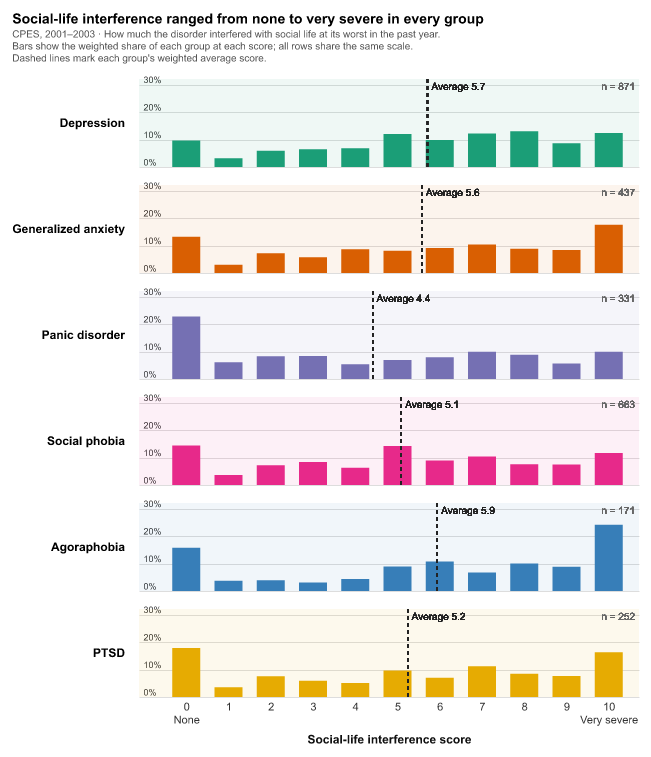

In [8]:
score_distributions, score_counts = [], []
for spec in DISORDERS.values():
    valid = (cpes[spec["diagnosis"]].eq(1)
             & cpes[spec["social"]].between(0, 10))
    counts = (cpes.loc[valid].groupby(spec["social"])["NCNLWTLG"].sum()
              .reindex(range(11), fill_value=0))
    score_distributions.append(counts / counts.sum() * 100)
    score_counts.append(int(valid.sum()))


distribution_df = pd.DataFrame([
    {"disorder": disorder, "n_label": f"n = {n:,}", "score": score,
     "share": float(distribution.loc[score]) / 100}
    for disorder, n, distribution in zip(DISORDER_LABELS, score_counts,
                                         score_distributions)
    for score in range(11)
])
# The weighted average score summarizes each row for comparison.
average_df = (
    distribution_df.assign(
        weighted=distribution_df["score"] * distribution_df["share"])
    .groupby(["disorder", "n_label"], as_index=False)["weighted"].sum()
    .rename(columns={"weighted": "average"})
)
average_df["average_label"] = ("Average "
                               + average_df["average"].round(1).astype(str))
distribution_df = distribution_df.merge(average_df,
                                        on=["disorder", "n_label"])


def interference_distributions(df):
    """
    Draw each disorder's distribution of social-life interference scores
    (Figure 5).

    Inputs:
      df (pd.DataFrame): one row per disorder and score (0-10), with
        share, n_label, average, and average_label columns.

    Returns:
      (alt.FacetChart) one row of bars per disorder, with a dashed line at
        the weighted average.
    """
    # Shade each row; the left margin gives its percentage labels their own
    # space.
    row_background = alt.Chart(df).transform_aggregate(
        groupby=["disorder"],
    ).mark_rect(opacity=.07).encode(
        x=alt.value(0), x2=alt.value(500), y=alt.value(0), y2=alt.value(88),
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    base = alt.Chart(df).encode(
        x=alt.X("score:Q", title="Social-life interference score",
                scale=alt.Scale(domain=[-1, 10.6], nice=False),
                # Name the endpoints of the scale under 0 and 10.
                axis=alt.Axis(values=list(range(11)), tickCount=11,
                              grid=False, labelAngle=0, labelOverlap=False,
                              labelLineHeight=13,
                              labelExpr="datum.value == 0 ? ['0', 'None'] : "
                                        "datum.value == 10 ? "
                                        "['10', 'Very severe'] : "
                                        "datum.label")),
        y=alt.Y("share:Q", title=None, stack=None,
                scale=alt.Scale(domain=[0, .32], nice=False),
                axis=alt.Axis(values=[0, .1, .2, .3], format=".0%",
                              tickCount=4, labelFontSize=9, labelPadding=-4,
                              labelAlign="left", labelBaseline="bottom",
                              labelOverlap=False, grid=True,
                              gridColor="#DDDDDD", gridOpacity=1)),
    )
    # Scores are whole numbers, so separate bars show them as distinct
    # values.
    bars = base.mark_bar(size=28).encode(
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    average = base.mark_rule(color="#222222", strokeWidth=1.5,
                             strokeDash=[4, 3]).encode(
        x="average:Q", y=alt.value(0), y2=alt.value(88),
    )
    average_text = base.mark_text(align="left", dx=4, fontSize=10,
                                  color="#222222").encode(
        x="average:Q", y=alt.value(8), text="average_label:N",
    )
    # Sample sizes sit apart from the disorder names, in smaller grey type.
    sample_size = base.mark_text(align="right", fontSize=10,
                                 color="#666666").encode(
        x=alt.value(496), y=alt.value(8), text="n_label:N",
    )
    profiles = (row_background + bars + average + average_text
                + sample_size).properties(width=500, height=88)
    return profiles.facet(
        row=alt.Row("disorder:N", sort=DISORDER_LABELS, title=None,
                    header=alt.Header(labelAngle=0, labelAlign="left",
                                      labelPadding=14, labelFontSize=12,
                                      labelFontWeight="bold")),
        spacing=14,
    ).resolve_scale(x="shared", y="shared")


save_chart(
    interference_distributions(distribution_df), "5.png",
    "Social-life interference ranged from none to very severe in every group",
    [CPES_SOURCE + " · How much the disorder interfered with social life at "
     "its worst in the past year.",
     "Bars show the weighted share of each group at each score; all rows "
     "share the same scale.",
     "Dashed lines mark each group's weighted average score."],
)

## Figure 6 · Disorder-specific professional care

Labels show known care answers / total past-year cases.

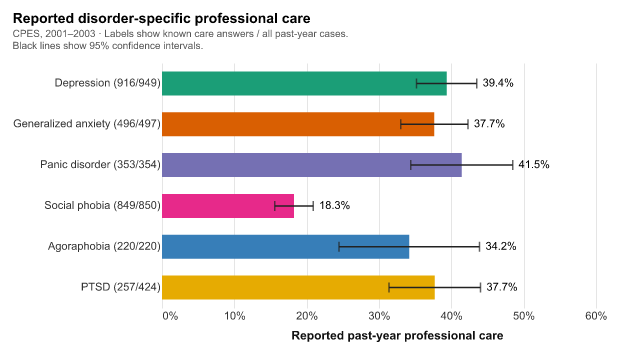

In [9]:
care_rows = []
# Estimate the share reporting professional care among each disorder's
# past-year cases; unknown care answers are left out.
for label, (name, spec), coverage in zip(DISORDER_LABELS, DISORDERS.items(),
                                         care_coverage):
    cases = cpes[spec["diagnosis"]].eq(1)
    result = survey_mean(cpes, care_values[name], cases, **CPES_DESIGN)
    care_rows.append({"label": label, "case_n": coverage["cases"], **result})
professional_care = pd.DataFrame(care_rows)


# Label each bar with known care answers out of all past-year cases.
care_plot = professional_care.assign(
    group=[f"{r.label} ({r.n}/{r.case_n})"
           for r in professional_care.itertuples()]
)


def professional_care_chart(df):
    """
    Draw the share reporting disorder-specific professional care, with
    95% CIs (Figure 6).

    Inputs:
      df (pd.DataFrame): one row per disorder, with group (label with
        counts), label, estimate, lower, and upper columns.

    Returns:
      (alt.LayerChart) bars, capped interval lines, and value labels.
    """
    base = alt.Chart(df).encode(
        y=alt.Y("group:N", sort=df["group"].tolist(), title=None),
        x=alt.X("estimate:Q", title="Reported past-year professional care",
                axis=alt.Axis(format="%"),
                scale=alt.Scale(domain=[0, .65], nice=False)),
    )
    # Bars, unlike Figure 4's markers, show this is a share of people.
    bars = base.mark_bar(size=24).encode(
        color=alt.Color("label:N", scale=DISORDER_SCALE, legend=None),
    )
    # Dark capped lines keep the 95% intervals visible over the bars.
    intervals = base.mark_rule(color="#222222", strokeWidth=1.5).encode(
        x="lower:Q", x2="upper:Q",
    )
    lower_caps = base.mark_tick(orient="vertical", color="#222222", size=10,
                                thickness=1.5).encode(x="lower:Q")
    upper_caps = base.mark_tick(orient="vertical", color="#222222", size=10,
                                thickness=1.5).encode(x="upper:Q")
    labels = base.mark_text(align="left", dx=6).encode(
        x="upper:Q", text=alt.Text("estimate:Q", format=".1%"),
    )
    return (bars + intervals + lower_caps + upper_caps
            + labels).properties(width=470, height=245)


save_chart(
    professional_care_chart(care_plot), "6.png",
    "Reported disorder-specific professional care",
    [CPES_SOURCE + " · Labels show known care answers / all past-year cases.",
     "Black lines show 95% confidence intervals."],
)

## Figure 7 · Interference and reported care

The two care measures use the same people in each score group. Antidepressant use is the one medication question asked of everyone, so it adds a broader view of treatment next to disorder-specific professional help; it may be for another condition. The score groups are not clinical severity categories.

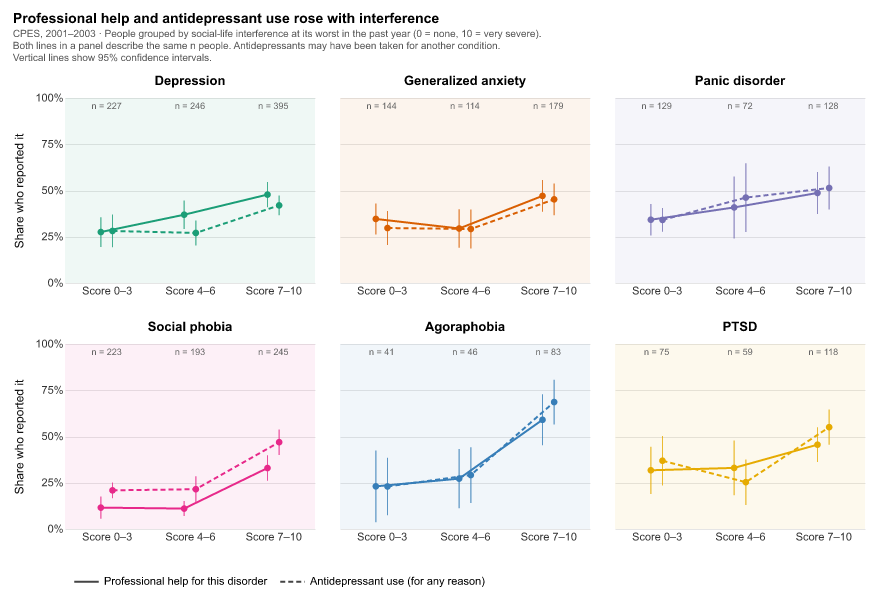

In [10]:
bands = [(0, 3), (4, 6), (7, 10)]
care_measures = ["Professional help for this disorder",
                 "Antidepressant use (for any reason)"]
interference_care_rows = []
antidepressants = cpes[ANTIDEPRESSANTS].map({1: 1., 5: 0.})

for label, (name, spec) in zip(DISORDER_LABELS, DISORDERS.items()):
    score = cpes[spec["social"]]
    # Both care measures use the same respondents within each disorder and
    # band.
    eligible = (cpes[spec["diagnosis"]].eq(1) & score.between(0, 10)
                & care_values[name].notna() & antidepressants.notna())
    measures = {care_measures[0]: care_values[name],
                care_measures[1]: antidepressants}
    for low, high in bands:
        group = eligible & score.between(low, high)
        band = f"{low}–{high}"
        for measure, values in measures.items():
            result = survey_mean(cpes, values, group, **CPES_DESIGN)
            interference_care_rows.append({"disorder": label, "band": band,
                                           "measure": measure, **result})

interference_care = pd.DataFrame(interference_care_rows)
interference_care["n_label"] = "n = " + interference_care["n"].astype(str)
# Place score groups at 0, 1, 2 and shift the two measures slightly apart.
band_position = {f"{low}–{high}": i for i, (low, high) in enumerate(bands)}
measure_shift = {care_measures[0]: -.07, care_measures[1]: .07}
interference_care["position"] = (
    interference_care["band"].map(band_position)
    + interference_care["measure"].map(measure_shift))
interference_care["band_position"] = (interference_care["band"]
                                      .map(band_position))


def interference_care_chart(df):
    """
    Draw professional help and antidepressant use by interference score
    group, one panel per disorder (Figure 7).

    Inputs:
      df (pd.DataFrame): one row per disorder, score band, and care
        measure, with position, band_position, estimate, lower, upper,
        and n_label columns.

    Returns:
      (alt.FacetChart) a panel of lines with 95% CIs for each disorder.
    """
    background = alt.Chart(df).transform_aggregate(
        groupby=["disorder"],
    ).mark_rect(opacity=.07).encode(
        x=alt.value(0), x2=alt.value(250), y=alt.value(0), y2=alt.value(185),
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    x_scale = alt.Scale(domain=[-.5, 2.5], nice=False)
    base = alt.Chart(df).encode(
        x=alt.X("position:Q", title=None, scale=x_scale,
                axis=alt.Axis(values=[0, 1, 2], grid=False,
                              labelOverlap=False,
                              labelExpr="['Score 0–3', 'Score 4–6', "
                                        "'Score 7–10'][datum.value]")),
        y=alt.Y("estimate:Q", title="Share who reported it",
                scale=alt.Scale(domain=[0, 1]),
                axis=alt.Axis(format="%", values=[0, .25, .5, .75, 1],
                              labelOverlap=False,
                              titleFontWeight="normal")),
        color=alt.Color("disorder:N", scale=DISORDER_SCALE, legend=None),
    )
    # Line style alone tells the two measures apart; lines only connect the
    # three groups.
    lines = base.mark_line(strokeWidth=2).encode(
        strokeDash=alt.StrokeDash(
            "measure:N", title=None,
            scale=alt.Scale(domain=care_measures, range=[[1, 0], [5, 3]]),
            legend=alt.Legend(orient="bottom", columns=2, labelLimit=300,
                              symbolType="stroke", symbolSize=600,
                              symbolStrokeWidth=2,
                              symbolStrokeColor="#444444")),
    )
    intervals = base.mark_rule(strokeWidth=1.2, opacity=.8).encode(
        y="lower:Q", y2="upper:Q",
    )
    points = base.mark_point(filled=True, size=45, opacity=1)
    # Respondent counts sit above each score group in small grey type.
    counts = alt.Chart(df).transform_filter(
        alt.datum.measure == care_measures[0],
    ).mark_text(
        fontSize=9, color="#666666",
    ).encode(x=alt.X("band_position:Q", scale=x_scale), y=alt.value(8),
             text="n_label:N")
    panel = (background + lines + intervals + points
             + counts).properties(width=250, height=185)
    return panel.facet(
        facet=alt.Facet("disorder:N", sort=DISORDER_LABELS, title=None,
                        header=alt.Header(labelFontSize=13,
                                          labelFontWeight="bold")),
        columns=3, spacing=25,
    ).resolve_axis(x="independent")


save_chart(
    interference_care_chart(interference_care), "7.png",
    "Professional help and antidepressant use rose with interference",
    [CPES_SOURCE + " · People grouped by social-life interference at its "
     "worst in the past year (0 = none, 10 = very severe).",
     "Both lines in a panel describe the same n people. Antidepressants may "
     "have been taken for another condition.",
     "Vertical lines show 95% confidence intervals."],
)

## Figure 8 · Depression-related care in 2024

[NSDUH 2024](https://www.samhsa.gov/data/data-we-collect/nsduh-national-survey-drug-use-and-health/datafiles/2024) asks about depression, impairment, and care together, so this section focuses on depression. It includes 5,008 adults with known care answers; 197 are excluded, including 145 with severe impairment. These results are separate from CPES.

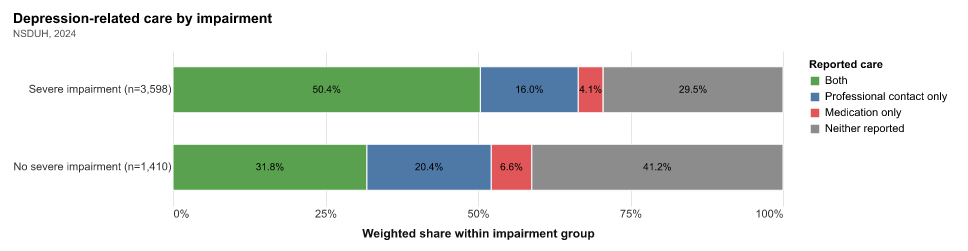

In [11]:
statuses = list(CARE_COLORS)

care_stack_rows = []
# IRAMDEIMP uses 1=severe role impairment; n counts adults with known
# answers to both care items.
impairment_groups = [(1, "Severe impairment (n=3,598)"),
                     (0, "No severe impairment (n=1,410)")]
for group_code, group_label in impairment_groups:
    group = nsduh_care.loc[nsduh_care["IRAMDEIMP"].eq(group_code)]
    # Weighted total for each care category, in legend order.
    totals = (group.groupby("care_group")["ANALWT2_C"].sum()
              .reindex(statuses, fill_value=0))
    # Track where each segment starts so its label sits at the center.
    cumulative = 0
    for order, status in enumerate(statuses):
        share = float(totals[status] / totals.sum())
        care_stack_rows.append({"impairment": group_label, "care": status,
                                "weight": float(totals[status]),
                                "share": share,
                                "middle": cumulative + share / 2,
                                "order": order})
        cumulative += share
care_stack_df = pd.DataFrame(care_stack_rows)
# Each impairment group's shares should add up to 100%.
assert np.allclose(care_stack_df.groupby("impairment")["share"].sum(), 1)


def care_combinations_chart(df):
    """
    Draw the mix of reported depression care within each impairment group
    as stacked bars (Figure 8).

    Inputs:
      df (pd.DataFrame): one row per impairment group and care category,
        with weight, share, middle (label position), and order columns.

    Returns:
      (alt.LayerChart) normalized stacked bars with percentage labels.
    """
    base = alt.Chart(df).encode(
        y=alt.Y("impairment:N",
                sort=df["impairment"].drop_duplicates().tolist(), title=None),
    )
    bars = base.mark_bar(size=46, stroke="white", strokeWidth=1).encode(
        x=alt.X("sum(weight):Q",
                title="Weighted share within impairment group",
                scale=alt.Scale(domain=[0, 1], nice=False))
          .stack("normalize").axis(format="%", values=[0, .25, .5, .75, 1]),
        color=alt.Color("care:N", title="Reported care",
                        scale=alt.Scale(domain=statuses,
                                        range=list(CARE_COLORS.values()))),
        order=alt.Order("order:Q", sort="ascending"),
    )
    labels = base.mark_text(fontSize=10, color="black").encode(
        x="middle:Q", text=alt.Text("share:Q", format=".1%"),
    )
    return (bars + labels).properties(width=610, height=155)


save_chart(
    care_combinations_chart(care_stack_df), "8.png",
    "Depression-related care by impairment",
    [NSDUH_SOURCE],
)

## Figure 9 · Insurance and reported care

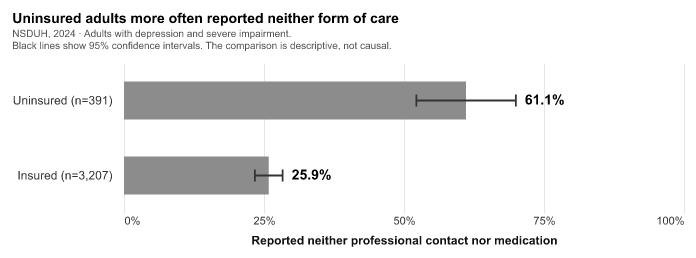

In [12]:
# neither is 1 when both care items are "no" and missing when either is
# unknown.
known = (nsduh_raw["ATXMDEYR"].isin([0, 1])
         & nsduh_raw["ARXMDEYR"].isin([0, 1]))
neither = ((nsduh_raw["ATXMDEYR"].eq(0) & nsduh_raw["ARXMDEYR"].eq(0))
           .astype(float).where(known))
# Adults with past-year depression and severe role impairment.
severe = nsduh_raw["IRAMDEYR"].eq(1) & nsduh_raw["IRAMDEIMP"].eq(1)
insurance_rows = []
# IRINSUR4 uses 1=insured and 2=uninsured. Use the full sample so the
# survey design stays intact.
for insurance_code, label in [(1, "Insured"), (2, "Uninsured")]:
    insured_group = severe & nsduh_raw["IRINSUR4"].eq(insurance_code)
    result = survey_mean(nsduh_raw, neither, insured_group, **NSDUH_DESIGN)
    insurance_rows.append({"label": label, **result})
insurance_rates = pd.DataFrame(insurance_rows)
assert insurance_rates["n"].tolist() == [3207, 391]


insurance_plot = insurance_rates.assign(
    group=[f"{r.label} (n={r.n:,})" for r in insurance_rates.itertuples()]
)


def insurance_care_chart(df):
    """
    Draw the share reporting neither form of care by insurance status,
    with 95% CIs (Figure 9).

    Inputs:
      df (pd.DataFrame): one row per insurance group, with group (label
        with n), estimate, lower, and upper columns.

    Returns:
      (alt.LayerChart) bars, capped interval lines, and value labels.
    """
    order = df.sort_values("estimate", ascending=False)["group"].tolist()
    base = alt.Chart(df).encode(
        y=alt.Y("group:N", title=None, sort=order,
                axis=alt.Axis(labelFontSize=12, labelPadding=12)),
        x=alt.X("estimate:Q",
                title="Reported neither professional contact nor medication",
                scale=alt.Scale(domain=[0, 1], nice=False),
                axis=alt.Axis(format="%", values=[0, .25, .5, .75, 1],
                              labelOverlap=False)),
    )
    bars = base.mark_bar(size=38, color=CARE_COLORS["Neither reported"])
    # Dark capped lines keep the 95% intervals visible over the bars.
    intervals = base.mark_rule(color="#333333", strokeWidth=1.8).encode(
        x="lower:Q", x2="upper:Q",
    )
    lower_caps = base.mark_tick(orient="vertical", color="#333333", opacity=1,
                                size=12, thickness=1.8).encode(x="lower:Q")
    upper_caps = base.mark_tick(orient="vertical", color="#333333", opacity=1,
                                size=12, thickness=1.8).encode(x="upper:Q")
    labels = base.mark_text(align="left", dx=9, fontSize=14,
                            fontWeight="bold").encode(
        x="upper:Q", text=alt.Text("estimate:Q", format=".1%"),
    )
    return (bars + intervals + lower_caps + upper_caps
            + labels).properties(width=560, height=150)


save_chart(
    insurance_care_chart(insurance_plot), "9.png",
    "Uninsured adults more often reported neither form of care",
    [NSDUH_SOURCE + " · Adults with depression and severe impairment.",
     "Black lines show 95% confidence intervals. The comparison is "
     "descriptive, not causal."],
)

## Figure 10 · Impairment, insurance, and care

This is a custom layout beyond the class examples. It groups survey weights by impairment, insurance, and care, then joins each group's positions between columns with smooth curves. Ribbon widths show shares of the full sample, not treatment rates within each group.

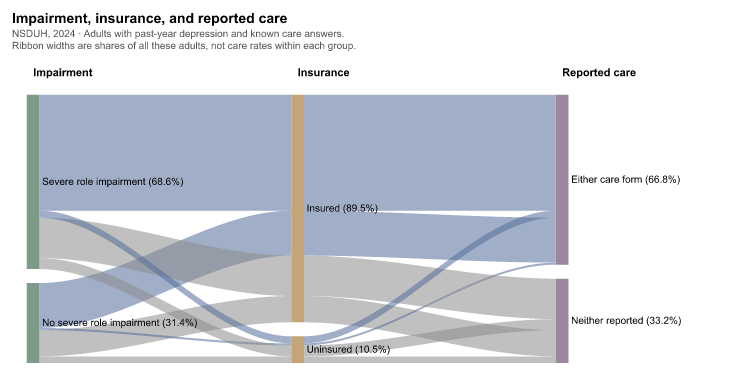

In [13]:
assert (nsduh_care["IRAMDEIMP"].isin([0, 1]).all()
        and nsduh_care["IRINSUR4"].isin([1, 2]).all())
# Find each group's weighted share of the sample.
paths = (nsduh_care.groupby(["IRAMDEIMP", "IRINSUR4", "reported_either"])
         ["ANALWT2_C"].sum())
paths = paths / paths.sum()
assert np.isclose(paths.sum(), 1) and len(paths) == 8
stage_names = ["Impairment", "Insurance", "Reported care"]
stage_colors = ["#7E9B89", "#C4A676", "#9D879F"]
stage_values = [[1, 0], [1, 2], [True, False]]
stage_labels = [["Severe role\nimpairment", "No severe role\nimpairment"],
                ["Insured", "Uninsured"],
                ["Either care form", "Neither reported"]]
nodes, slots = {}, {}
gap = .055
# Place the groups from top to bottom in each column.
for stage, values in enumerate(stage_values):
    cursor = 1 + gap
    for value in values:
        members = [p for p in paths.index if p[stage] == value]
        total = sum(paths[p] for p in members)
        top, bottom = cursor, cursor - total
        nodes[stage, value] = (bottom, top, total)
        offset = top
        for p in sorted(members, key=lambda p: (not p[2], -p[0], p[1])):
            slots[stage, p] = (offset - paths[p], offset)
            offset -= paths[p]
        assert np.isclose(offset, bottom)
        cursor = bottom - gap


ribbon_rows, node_rows = [], []
# Connect matching groups in neighboring columns with smooth ribbons.
for path, share in paths.items():
    for stage in [0, 1]:
        low0, high0 = slots[stage, path]
        low1, high1 = slots[stage + 1, path]
        for fraction in np.linspace(0, 1, 41):
            smooth = fraction * fraction * (3 - 2 * fraction)
            low = low0 + (low1 - low0) * smooth
            high = high0 + (high1 - high0) * smooth
            assert np.isclose(high - low, share)
            care = "Either care form" if path[2] else "Neither reported"
            ribbon_rows.append({"ribbon": str(path) + str(stage),
                                "x": stage * .5 + .012 + fraction * .476,
                                "low": low, "high": high, "care": care})
for stage, values in enumerate(stage_values):
    for value, label in zip(values, stage_labels[stage]):
        bottom, top, share = nodes[stage, value]
        node_rows.append({"stage": stage_names[stage], "x": stage * .5,
                          "left": stage * .5 - .012,
                          "right": stage * .5 + .012,
                          "low": bottom, "high": top,
                          "middle": (bottom + top) / 2,
                          "label": (label.replace("\n", " ")
                                    + f" ({share:.1%})")})
ribbon_df = pd.DataFrame(ribbon_rows)
node_df = pd.DataFrame(node_rows)
stage_df = pd.DataFrame({"x": [0, .5, 1], "label": stage_names})


def impairment_insurance_care_chart(ribbons, nodes, stages):
    """
    Draw a flow diagram from impairment to insurance to reported care
    (Figure 10).

    Inputs:
      ribbons (pd.DataFrame): points along each ribbon, with ribbon, x,
        low, high, and care columns.
      nodes (pd.DataFrame): one row per group bar, with stage, x, left,
        right, low, high, middle, and label columns.
      stages (pd.DataFrame): the x position and label of each column
        heading.

    Returns:
      (alt.LayerChart) ribbons, group bars, group labels, and headings.
    """
    xs = alt.Scale(domain=[-.04, 1.34], nice=False)
    ys = alt.Scale(domain=[0, 1.18], nice=False)
    care_scale = alt.Scale(domain=["Either care form", "Neither reported"],
                           range=[BLUE, CARE_COLORS["Neither reported"]])
    flow = alt.Chart(ribbons).mark_area(orient="vertical",
                                        opacity=.55).encode(
        x=alt.X("x:Q", scale=xs, axis=None),
        y=alt.Y("low:Q", scale=ys, axis=None, stack=None), y2="high:Q",
        detail="ribbon:N",
        color=alt.Color("care:N", title="Reported care", scale=care_scale,
                        legend=None),
    )
    bars = alt.Chart(nodes).mark_rect().encode(
        x=alt.X("left:Q", scale=xs, axis=None), x2="right:Q",
        y=alt.Y("low:Q", scale=ys, axis=None), y2="high:Q",
        color=alt.Color("stage:N",
                        scale=alt.Scale(domain=stage_names,
                                        range=stage_colors),
                        legend=None),
    )
    labels = alt.Chart(nodes).mark_text(align="left", dx=9,
                                        fontSize=10).encode(
        x=alt.X("x:Q", scale=xs, axis=None),
        y=alt.Y("middle:Q", scale=ys, axis=None), text="label:N",
    )
    headings = alt.Chart(stages).mark_text(align="left",
                                           fontWeight="bold").encode(
        x=alt.X("x:Q", scale=xs, axis=None), y=alt.datum(1.14),
        text="label:N",
    )
    # Column colors identify stages; ribbons keep their care-category colors.
    return (flow + bars + labels + headings).properties(
        width=730, height=300,
    ).resolve_scale(color="independent")


save_chart(
    impairment_insurance_care_chart(ribbon_df, node_df, stage_df), "10.png",
    "Impairment, insurance, and reported care",
    [NSDUH_SOURCE + " · Adults with past-year depression and known care "
     "answers.",
     "Ribbon widths are shares of all these adults, not care rates within "
     "each group."],
)